# Notebook 01c · Spatially Stratified Train/Test Split + Spatial CV

> **All points, no train/test split** (branch `main`). Every point tunes the
> random forest by spatial-block CV and fits the final model; accuracy is the
> spatial CV and the EarthLabel validation (notebook 05). The split design,
> with a held-out test set, is on branch `train-test-split`.

## IMD Prediction — Full Spatial Independence Design
### Random forest · Spatial HP Tuning · GEE Raster · Spatial Holdout Evaluation

**Design:**
```
All 3500 points
│
├── Spatial 1km block split (random block assignment)
│   Buffer 250m between train and test
│   -> TRAIN (~70%)          TEST (~30%, locked away)
│
└── On TRAIN only:
     Spatial block CV (500m/1km/2km) for HP tuning
     -> best block size per model
     -> retrain on full TRAIN with best HPs
     -> evaluate on TEST once (final accuracy)
```

---
## Cell 1 · Imports & configuration

In [ ]:
# Earth Engine project id comes from .env (copy .env.example to .env).
# Authentication is a one-off per machine: run `earthengine authenticate`.
import ee
from gee_init import init_gee

init_gee()

NameError: name 'ee' is not defined

In [48]:
import os, pyproj
_proj = pyproj.datadir.get_data_dir()
os.environ['PROJ_LIB']  = _proj
os.environ['PROJ_DATA'] = _proj

In [2]:
# Earth Engine project id comes from .env (copy .env.example to .env).
# Authentication is a one-off per machine: run `earthengine authenticate`.
import ee
from gee_init import init_gee
from gee_export import start_export, wait_and_download
import sample_features as sf
from gee_models import (RF_PARAM_SPACE, rf_classifier, rf_gee_params,
                        training_fc, compare_predictions)

init_gee()

import geemap
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from scipy.spatial import cKDTree
import matplotlib.ticker as mticker
import warnings, os, time, json
import joblib
import rioxarray as rxr
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')
# ── Configuration ──────────────────────────────────────────────────────────────
from gee_init import get_project
GEE_PROJECT    = get_project()   # from .env
AEF_YEAR       = 2018
RANDOM_STATE   = 42
N_JOBS         = 1
N_FOLDS        = 5        # CV folds within training set
INNER_CV       = 5        # inner folds for HP tuning (can be changed, for example 3 or 5)
BUFFER_M       = 250      # buffer between train/test and between CV folds
SPLIT_BLOCK_M  = 1000     # block size for train/test split
BLOCK_SIZES    = [500, 1000, 2000]   # block sizes tested for HP tuning CV
TEST_FRAC      = 0.30     # target test fraction
N_ITER_RF      = 40
N_CLASSES      = 7
# ── Paths ──────────────────────────────────────────────────────────────────────
OUTPUT_DIR      = './output/milan/clms/embedding'
RF_RASTER_PATH  = f'{OUTPUT_DIR}/IMD_predicted_RF_spatialCV2_Milan.tif'
os.makedirs(OUTPUT_DIR, exist_ok=True)
# ── Plot style ─────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 130, 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
CLASS_COLORS = ['#2166ac','#74add1','#abd9e9','#fee090','#f46d43','#d73027','#a50026']
CLASS_LABELS = ['C0 (0%)','C1 (1-20%)','C2 (21-40%)','C3 (41-60%)','C4 (61-80%)','C5 (81-99%)','C6 (100%)']
MODEL_COLORS = {'RF': '#2ecc71'}
CV_LABELS    = ['Random'] + [f'{bs}m' for bs in BLOCK_SIZES]
print('Setup OK')
print(f'Split block: {SPLIT_BLOCK_M}m | Buffer: {BUFFER_M}m | Target test: {TEST_FRAC*100:.0f}%')
print(f'CV folds: {N_FOLDS} outer / {INNER_CV} inner | Block sizes: {BLOCK_SIZES} m')

EEException: Caller does not have required permission to use project ee-xiaoo. Grant the caller the roles/serviceusage.serviceUsageConsumer role, or a custom role with the serviceusage.services.use permission, by visiting https://console.developers.google.com/iam-admin/iam?project=ee-xiaoo and then retry. Propagation of the new permission may take a few minutes.

---
## Cell 2 · Load GEE assets & all 3500 points

In [50]:
# ── GEE ───────────────────────────────────────────────────────────────────────
aoi      = ee.FeatureCollection(f'projects/{GEE_PROJECT}/assets/milano_aoi')
aoi_geom = aoi.geometry()

non_water_mask = (ee.ImageCollection('ESA/WorldCover/v200')
                  .filter(ee.Filter.bounds(aoi_geom))
                  .mosaic().clip(aoi_geom)).neq(80)

start_date = ee.Date.fromYMD(AEF_YEAR, 1, 1)
aef_col    = (ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
              .filter(ee.Filter.date(start_date, start_date.advance(1, 'year')))
              .filter(ee.Filter.bounds(aoi_geom)))
aef_proj   = aef_col.first().projection()
aef_img    = (aef_col.mosaic()
              .setDefaultProjection(aef_proj)
              .clip(aoi_geom)
              .updateMask(non_water_mask))

band_names = aef_img.bandNames().getInfo()
print(f'AEF bands: {len(band_names)}')

# ── Points, labels, split and embedding bands (notebook 00) ───────────────────
gdf_all, feat_meta = sf.load_features('CLMS', 'Milan', 'embedding')
assert feat_meta['band_names'] == band_names, (
    'Feature table bands differ from the AlphaEarth image; re-run notebook 00.')

gdf_utm = gdf_all.to_crs('EPSG:32632')
coords_all = np.column_stack([gdf_utm.geometry.x, gdf_utm.geometry.y])

X_all = gdf_all[band_names].values.astype(np.float32)
y_all = gdf_all['IMD'].values.astype(np.float32)

print(f'Total points: {len(gdf_all)}')
print(f'X shape: {X_all.shape} | y range: {y_all.min():.0f}-{y_all.max():.0f}%')
print(f'Class distribution:')
for c in range(N_CLASSES):
    n = int((gdf_all['IMD_class']==c).sum())
    print(f'  {CLASS_LABELS[c]}: {n}')


AEF bands: 64
Total points: 3500
X shape: (3500, 64) | y range: 0-100%
Class distribution:
  C0 (0%): 500
  C1 (1-20%): 500
  C2 (21-40%): 500
  C3 (41-60%): 500
  C4 (61-80%): 500
  C5 (81-99%): 500
  C6 (100%): 500


---
## Cell 3 · Spatial block functions

In [51]:
# ── Spatial block helper functions ────────────────────────────────────────────
def assign_blocks(coords, block_size):
    bx = (coords[:, 0] // block_size).astype(int)
    by = (coords[:, 1] // block_size).astype(int)
    return np.array([f'{x}_{y}' for x, y in zip(bx, by)])

def blocks_to_folds(block_ids, n_folds, seed):
    rng    = np.random.RandomState(seed)
    unique = rng.permutation(np.unique(block_ids))
    bmap   = {b: i % n_folds for i, b in enumerate(unique)}
    return np.array([bmap[b] for b in block_ids]), bmap

def apply_buffer(train_coords, test_coords, buffer_m):
    if len(train_coords) == 0 or buffer_m == 0:
        return np.ones(len(test_coords), dtype=bool)
    dists, _ = cKDTree(train_coords).query(test_coords, k=1)
    return dists > buffer_m

def make_spatial_splits(point_folds, n_folds):
    all_idx = np.arange(len(point_folds))
    return [(all_idx[point_folds != f], all_idx[point_folds == f])
            for f in range(n_folds)]

print('Spatial block functions defined.')


Spatial block functions defined.


---
## Cell 4 · All points

No train/test split: every point of the feature table is used both to tune the
random forest (spatial-block CV, next cells) and to fit the final model.
Accuracy comes from that spatial CV and, independently, from the EarthLabel
plots (notebook 05). The table's `split` column is used only on the
`train-test-split` branch.

In [ ]:
# ── All points: no train/test split ──────────────────────────────────────────
# Every point tunes (spatial-block CV) and fits the final model. The names
# below keep the *_train suffix so the CV cells read unchanged: here the
# "training set" is all points.
X_train, y_train = X_all, y_all
coords_train     = coords_all
gdf_train        = gdf_all
print(f'Points used for tuning and fitting: {len(gdf_train)}')

# Saved for notebooks 02/03, which train the zero-shot forest on these points.
gdf_train.to_file(f'{OUTPUT_DIR}/training_pts.gpkg', driver='GPKG')
print(f'Saved {OUTPUT_DIR}/training_pts.gpkg')


---
## Cell 6 · Hyperparameter tuning (spatial block CV, all points)

In [54]:
# ── Hyperparameter tuning with 5-fold spatial block CV (training set only) ────
# For each model, RandomizedSearchCV uses spatial block folds of the TRAINING set.
# Three block sizes tested; best block size selected by lowest spatial CV RMSE.

spatial_folds_tune = {}
for bs in BLOCK_SIZES:
    bids = assign_blocks(coords_train, bs)
    pf, _ = blocks_to_folds(bids, N_FOLDS, RANDOM_STATE)
    spatial_folds_tune[bs] = pf

# RF only, tuned over the settings Earth Engine can reproduce exactly, so the
# exported raster is the tuned model (gee_models.py).
param_spaces    = {'RF': RF_PARAM_SPACE}
base_estimators = {'RF': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS)}
n_iters         = {'RF': N_ITER_RF}

tuned_models         = {}
best_block_per_model = {}
tune_rows            = []

for name in ['RF']:
    print(f'\n{"="*55}')
    print(f'  {name} -- tuning on TRAINING set ({N_FOLDS}-fold spatial CV)')
    print(f'{"="*55}')
    model_best_rmse   = np.inf
    model_best_search = None
    model_best_block  = None

    for bs in BLOCK_SIZES:
        label     = f'{bs}m'
        cv_splits = make_spatial_splits(spatial_folds_tune[bs], N_FOLDS)

        print(f'  {label} ... ', end='', flush=True)
        t0     = time.time()
        search = RandomizedSearchCV(
            estimator           = base_estimators[name],
            param_distributions = param_spaces[name],
            n_iter              = n_iters[name],
            cv                  = cv_splits,
            scoring             = 'neg_root_mean_squared_error',
            n_jobs              = N_JOBS,
            random_state        = RANDOM_STATE,
            refit               = True
        )
        search.fit(X_train, y_train)
        cv_rmse = -search.best_score_
        cv_std  = search.cv_results_['std_test_score'][search.best_index_]
        print(f'{time.time()-t0:.1f}s | CV RMSE={cv_rmse:.3f} ± {cv_std:.3f}')
        print(f'          best params: {search.best_params_}')

        tune_rows.append({'Model': name, 'Block': label,
                           'CV_RMSE': round(cv_rmse, 3),
                           'CV_std':  round(cv_std, 3),
                           'Best_params': str(search.best_params_)})

        if cv_rmse < model_best_rmse:
            model_best_rmse   = cv_rmse
            model_best_search = search
            model_best_block  = label

    tuned_models[name]         = model_best_search.best_estimator_
    best_block_per_model[name] = model_best_block
    print(f'  => Best block for {name}: {model_best_block}  CV RMSE={model_best_rmse:.3f}')

tune_df = pd.DataFrame(tune_rows)
tune_df.to_csv(f'{OUTPUT_DIR}/hyperparameter_tuning.csv', index=False)

print('\n' + '=='*28)
print('  TUNING SUMMARY')
print('=='*28)
for name in tuned_models:
    b    = best_block_per_model[name]
    row  = tune_df[(tune_df['Model']==name) & (tune_df['Block']==b)].iloc[0]
    print(f'  {name:<8}: best block={b}  CV RMSE={row["CV_RMSE"]:.3f} ± {row["CV_std"]:.3f}')
print('=='*28)
print('\nHyperparameter tuning complete.')



  RF -- tuning on TRAINING set (5-fold spatial CV)
  500m ... 618.5s | CV RMSE=13.204 ± 0.273
          best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_samples': 0.9, 'max_features': 0.3, 'max_depth': None}
  1000m ... 624.5s | CV RMSE=13.162 ± 0.502
          best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_samples': 0.9, 'max_features': 0.3, 'max_depth': None}
  2000m ... 620.1s | CV RMSE=13.172 ± 0.476
          best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_samples': 0.9, 'max_features': 0.3, 'max_depth': None}
  => Best block for RF: 1000m  CV RMSE=13.162

  SVR -- tuning on TRAINING set (5-fold spatial CV)
  500m ... 893.0s | CV RMSE=11.711 ± 0.244
          best params: {'svr__kernel': 'rbf', 'svr__gamma': 0.001, 'svr__epsilon': 0.1, 'svr__C': 500}
  1000m ... 545.8s | CV RMSE=11.793 ± 0.582
          best params: {'svr__kernel': 'rbf', 'svr__gamma': 0.001, 'svr_

---
## Cell 7 · Spatial CV evaluation, all points

In [55]:
# ── Spatial CV evaluation on training set (quantify autocorrelation inflation) ─
# This mirrors the design in 01b but operates only on the training set.
# Gives honest CV estimates; test set still untouched.

def run_spatial_cv(model_template, X, y, coords,
                   point_folds, n_folds, buffer_m, is_spatial):
    rows = []
    for fold in range(n_folds):
        tr = point_folds != fold
        te = point_folds == fold
        Xtr, ytr = X[tr], y[tr]
        Xte, yte = X[te], y[te]

        if is_spatial and buffer_m > 0:
            keep = apply_buffer(coords[tr], coords[te], buffer_m)
            Xte, yte = Xte[keep], yte[keep]
            n_removed = (~keep).sum()
        else:
            n_removed = 0

        if len(yte) < 10:
            continue

        m = clone(model_template)
        m.fit(Xtr, ytr)
        yp = np.clip(m.predict(Xte), 0, 100)

        rows.append({
            'fold':      fold,
            'n_train':   int(Xtr.shape[0]),
            'n_test':    int(len(yte)),
            'n_removed': int(n_removed),
            'pct_rem':   round(100 * n_removed / max(te.sum(), 1), 1),
            'RMSE':      float(np.sqrt(mean_squared_error(yte, yp))),
            'MAE':       float(mean_absolute_error(yte, yp)),
            'R2':        float(r2_score(yte, yp)),
            'Bias':      float(np.mean(yte - yp)),
        })
    return pd.DataFrame(rows)

# Pre-compute outer evaluation folds (on training set only)
random_folds_tr = np.zeros(len(X_train), dtype=int)
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fi, (_, tidx) in enumerate(kf.split(X_train)):
    random_folds_tr[tidx] = fi

spatial_folds_eval = {}
for bs in BLOCK_SIZES:
    bids = assign_blocks(coords_train, bs)
    pf, _ = blocks_to_folds(bids, N_FOLDS, RANDOM_STATE)
    spatial_folds_eval[bs] = pf
    n_blocks = len(np.unique(bids))
    counts   = [int((pf==f).sum()) for f in range(N_FOLDS)]
    print(f'{bs}m: {n_blocks} blocks | pts/fold: {counts}')

all_results = {}
total = len(tuned_models) * (1 + len(BLOCK_SIZES))
run_i = 0

for name, model in tuned_models.items():
    run_i += 1
    print(f'\n[{run_i}/{total}] {name} x Random (training set CV)')
    t0 = time.time()
    df = run_spatial_cv(model, X_train, y_train, coords_train,
                        random_folds_tr, N_FOLDS, 0, is_spatial=False)
    print(f'  {time.time()-t0:.1f}s | RMSE: {df["RMSE"].mean():.2f} +/- {df["RMSE"].std():.2f}')
    all_results[(name, 'Random')] = df

    for bs in BLOCK_SIZES:
        run_i += 1
        label = f'{bs}m'
        print(f'[{run_i}/{total}] {name} x {label} (buffer={BUFFER_M}m)')
        t0 = time.time()
        df = run_spatial_cv(model, X_train, y_train, coords_train,
                            spatial_folds_eval[bs], N_FOLDS, BUFFER_M, is_spatial=True)
        print(f'  {time.time()-t0:.1f}s | RMSE: {df["RMSE"].mean():.2f} +/- {df["RMSE"].std():.2f} | ' +
              f'buffer removed: {df["pct_rem"].mean():.1f}%')
        all_results[(name, label)] = df

print(f'\nAll {total} CV runs complete.')


500m: 2079 blocks | pts/fold: [490, 488, 492, 486, 493]
1000m: 1478 blocks | pts/fold: [497, 472, 489, 495, 496]
2000m: 839 blocks | pts/fold: [510, 500, 505, 445, 489]

[1/12] RF x Random (training set CV)
  15.5s | RMSE: 13.33 +/- 0.61
[2/12] RF x 500m (buffer=250m)
  15.2s | RMSE: 13.23 +/- 0.32 | buffer removed: 6.2%
[3/12] RF x 1000m (buffer=250m)
  14.9s | RMSE: 13.17 +/- 0.57 | buffer removed: 3.2%
[4/12] RF x 2000m (buffer=250m)
  15.1s | RMSE: 13.19 +/- 0.56 | buffer removed: 2.0%

[5/12] SVR x Random (training set CV)
  1.4s | RMSE: 11.59 +/- 0.60
[6/12] SVR x 500m (buffer=250m)
  1.3s | RMSE: 11.55 +/- 0.31 | buffer removed: 6.2%
[7/12] SVR x 1000m (buffer=250m)
  1.4s | RMSE: 11.64 +/- 0.67 | buffer removed: 3.2%
[8/12] SVR x 2000m (buffer=250m)
  1.3s | RMSE: 11.65 +/- 0.64 | buffer removed: 2.0%

[9/12] MLP x Random (training set CV)
  11.7s | RMSE: 11.98 +/- 0.77
[10/12] MLP x 500m (buffer=250m)
  11.8s | RMSE: 11.90 +/- 0.22 | buffer removed: 6.2%
[11/12] MLP x 1000m (b

## Test 5 times repeating the folding and then see the mean and stdev

In [56]:
from tqdm import tqdm

N_REPEATS = 5

def run_spatial_cv_repeated(model_template, X, y, coords,
                             block_size, n_folds, buffer_m, is_spatial, n_repeats):
    all_rows = []
    for rep in tqdm(range(n_repeats), desc=f'{"Spatial" if is_spatial else "Random"} {block_size or ""}m', leave=False):
        if is_spatial:
            bids = assign_blocks(coords, block_size)
            pf, _ = blocks_to_folds(bids, n_folds, seed=RANDOM_STATE + rep)
        else:
            pf = np.zeros(len(X), dtype=int)
            kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE + rep)
            for fi, (_, tidx) in enumerate(kf.split(X)):
                pf[tidx] = fi

        df = run_spatial_cv(model_template, X, y, coords, pf, n_folds, buffer_m, is_spatial)
        df['repeat'] = rep
        all_rows.append(df)

    return pd.concat(all_rows, ignore_index=True)

In [57]:
for name, model in tqdm(tuned_models.items(), desc='Models'):
    for bs_label, bs, spatial in (
        [('Random', None, False)] + [(f'{bs}m', bs, True) for bs in BLOCK_SIZES]
    ):
        tqdm.write(f'  {name} x {bs_label}')
        df = run_spatial_cv_repeated(
            model, X_train, y_train, coords_train,
            block_size=bs, n_folds=N_FOLDS,
            buffer_m=BUFFER_M if spatial else 0,
            is_spatial=spatial, n_repeats=N_REPEATS
        )
        all_results[(name, bs_label)] = df

Models:   0%|          | 0/3 [00:00<?, ?it/s]

  RF x Random


Models:   0%|          | 0/3 [01:14<?, ?it/s]

  RF x 500m


Models:   0%|          | 0/3 [02:28<?, ?it/s]

...

Models:  67%|██████▋   | 2/3 [07:15<02:17, 137.21s/it]

  MLP x 1000m


Models:  67%|██████▋   | 2/3 [08:10<02:17, 137.21s/it]

  MLP x 2000m


Models: 100%|██████████| 3/3 [09:06<00:00, 182.05s/it]


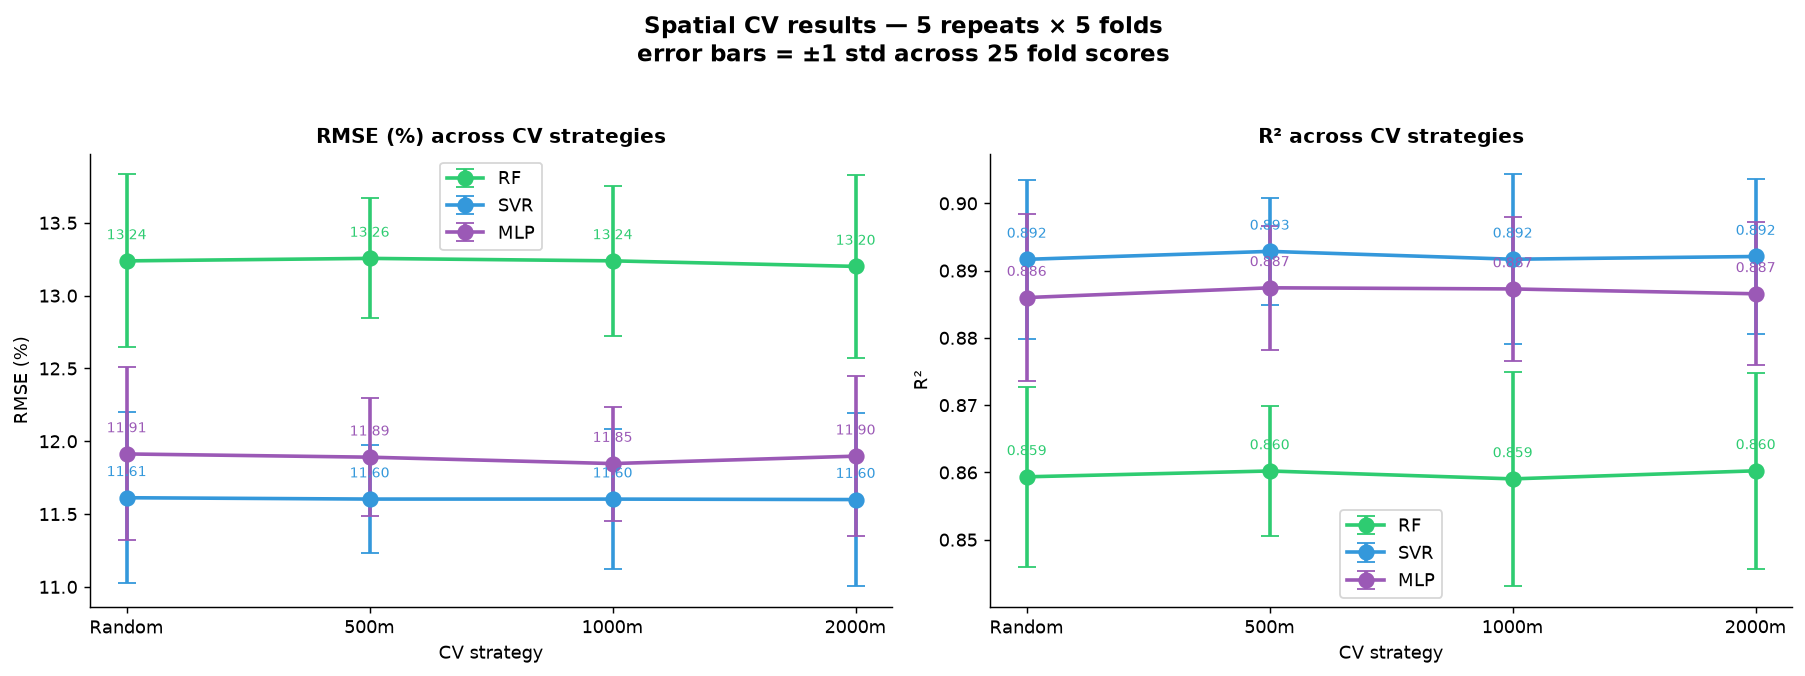

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, ax, ylabel in [('RMSE', axes[0], 'RMSE (%)'), ('R2', axes[1], 'R²')]:
    for name in tuned_models:
        means = [all_results[(name, l)][metric].mean() for l in CV_LABELS]
        stds  = [all_results[(name, l)][metric].std()  for l in CV_LABELS]
        ax.errorbar(range(len(CV_LABELS)), means, yerr=stds,
                    fmt='o-', color=MODEL_COLORS[name], lw=2, ms=8,
                    capsize=5, label=name)
        for i, m in enumerate(means):
            ax.annotate(f'{m:.2f}' if metric=='RMSE' else f'{m:.3f}',
                        (i, m), textcoords='offset points',
                        xytext=(0, 12), ha='center', fontsize=8,
                        color=MODEL_COLORS[name])

    ax.set_xticks(range(len(CV_LABELS)))
    ax.set_xticklabels(CV_LABELS)
    ax.set_xlabel('CV strategy')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} across CV strategies', fontweight='bold')
    ax.legend(fontsize=10)

fig.suptitle(f'{N_REPEATS} repeats × {N_FOLDS} folds  ·  error bars = ±1 std across {N_REPEATS * N_FOLDS} fold scores',
             fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_repeated_cv_results.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 8 · Summary table & best model selection

In [59]:
# Summary table
rows = []
for name in tuned_models:
    for label in CV_LABELS:
        df = all_results[(name, label)]
        rows.append({
            'Model':       name,
            'CV_method':   label,
            'RMSE_mean':   round(df['RMSE'].mean(), 2),
            'RMSE_std':    round(df['RMSE'].std(), 2),
            'MAE_mean':    round(df['MAE'].mean(), 2),
            'MAE_std':     round(df['MAE'].std(), 2),
            'R2_mean':     round(df['R2'].mean(), 3),
            'R2_std':      round(df['R2'].std(), 3),
            'Bias_mean':   round(df['Bias'].mean(), 2),
            'Bias_std':    round(df['Bias'].std(), 2),
            'pct_rem_avg': round(df['pct_rem'].mean(), 1),
        })
summary_df = pd.DataFrame(rows)
summary_df.to_csv(f'{OUTPUT_DIR}/spatial_cv_summary.csv', index=False)

print('=='*35)
print(f'  SPATIAL CV (training set) -- buffer={BUFFER_M}m, {N_FOLDS}-fold')
print('=='*35)
print(summary_df.to_string(index=False))
print('=='*35)

# Best model overall
spatial_labels = [f'{bs}m' for bs in BLOCK_SIZES]
best_rmse = np.inf
BEST_MODEL_NAME  = None
BEST_BLOCK_LABEL = None
for name in tuned_models:
    label = best_block_per_model[name]
    rmse  = all_results[(name, label)]['RMSE'].mean()
    if rmse < best_rmse:
        best_rmse        = rmse
        BEST_MODEL_NAME  = name
        BEST_BLOCK_LABEL = label

BEST_MODEL = tuned_models[BEST_MODEL_NAME]
print(f'\n* Overall best: {BEST_MODEL_NAME} @ {BEST_BLOCK_LABEL}  RMSE={best_rmse:.3f}%')
print(f'  -> GEE raster + holdout evaluation')


  SPATIAL CV (training set) -- buffer=250m, 5-fold
Model CV_method  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std  Bias_mean  Bias_std  pct_rem_avg
   RF    Random      13.24      0.59      9.88     0.45    0.859   0.013      -0.01      0.59          0.0
   RF      500m      13.26      0.41      9.85     0.31    0.860   0.010      -0.07      0.61          6.5
   RF     1000m      13.24      0.51      9.86     0.42    0.859   0.016      -0.04      0.57          3.2
   RF     2000m      13.20      0.63      9.85     0.47    0.860   0.015      -0.01      0.58          1.8
  SVR    Random      11.61      0.59      8.37     0.43    0.892   0.012      -0.29      0.57          0.0
  SVR      500m      11.60      0.37      8.33     0.29    0.893   0.008      -0.40      0.64          6.5
  SVR     1000m      11.60      0.48      8.36     0.40    0.892   0.013      -0.32      0.43          3.2
  SVR     2000m      11.60      0.59      8.36     0.41    0.892   0.011      -0.31      0.66

---
## Cell 9 · Figure 2 — CV fold maps

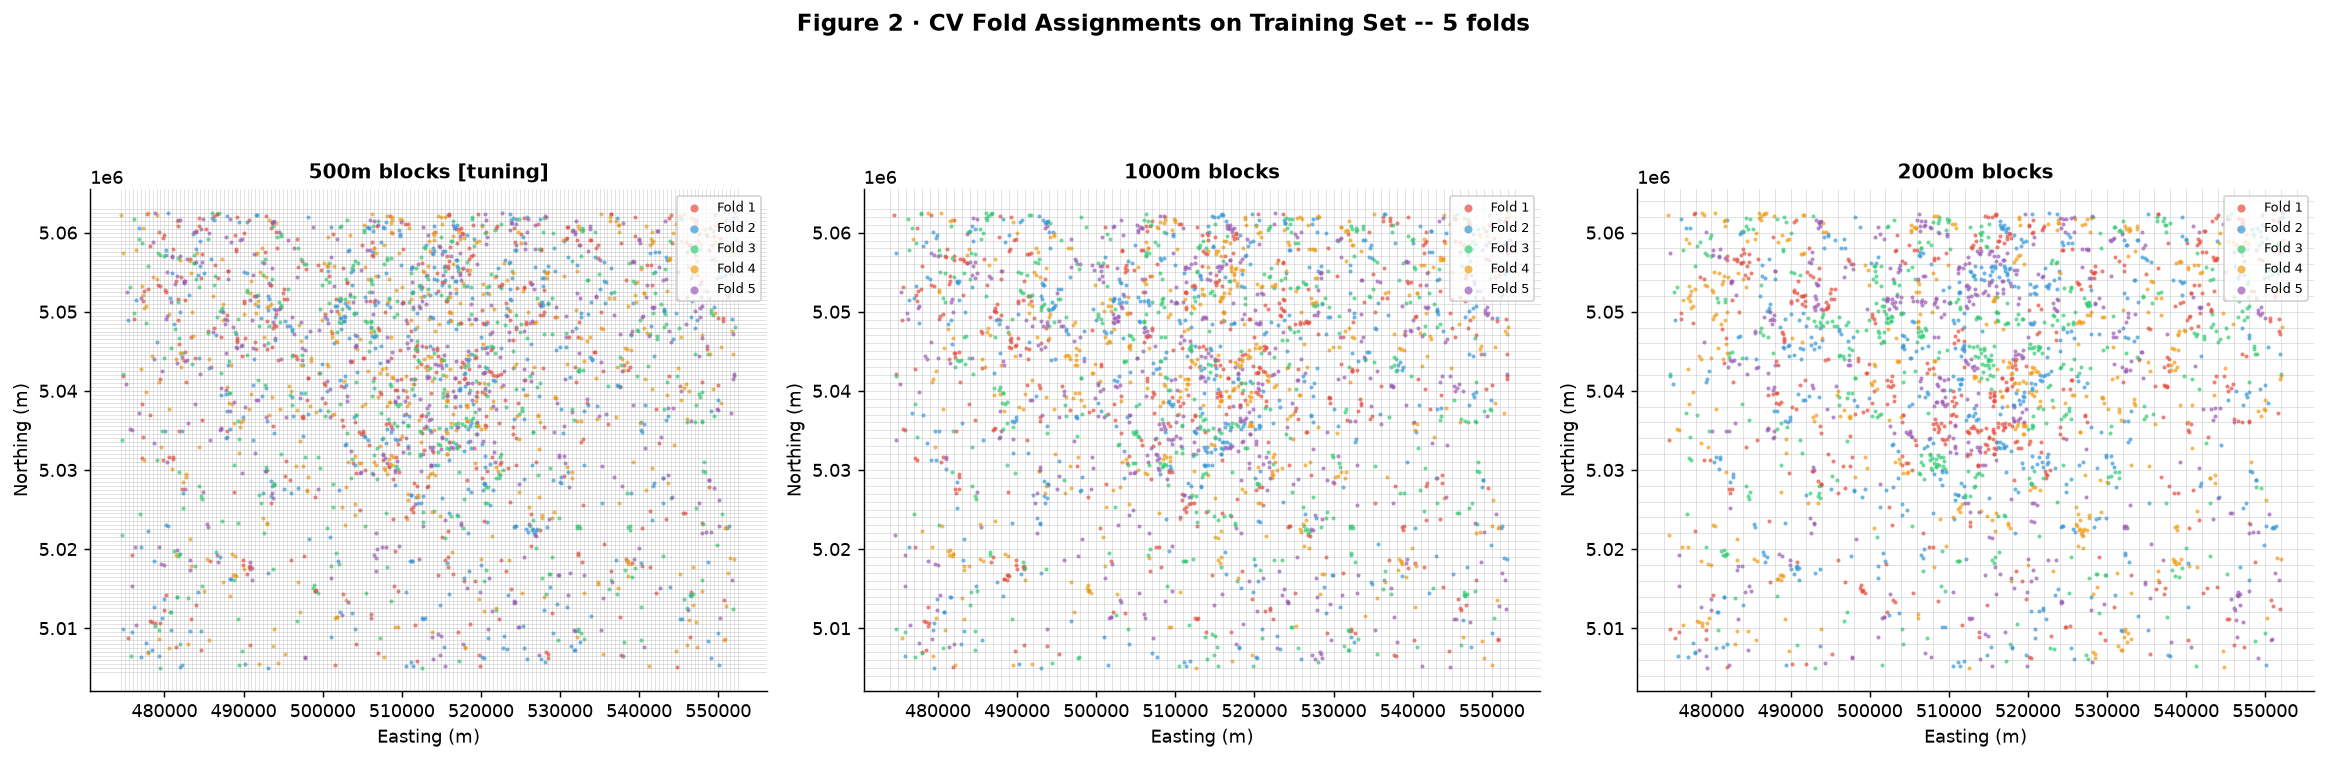

Figure 2 saved.


In [60]:
# Figure 2 -- CV fold maps on training set
fold_colors = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, bs in zip(axes, BLOCK_SIZES):
    pf = spatial_folds_eval[bs]
    for fold in range(N_FOLDS):
        m = pf == fold
        ax.scatter(coords_train[m, 0], coords_train[m, 1],
                   c=fold_colors[fold], s=5, alpha=0.7,
                   label=f'Fold {fold+1}', linewidths=0)
    x0, x1 = coords_train[:,0].min(), coords_train[:,0].max()
    y0, y1 = coords_train[:,1].min(), coords_train[:,1].max()
    for x in np.arange(x0 // bs * bs, x1 + bs, bs):
        ax.axvline(x, color='grey', lw=0.3, alpha=0.4)
    for y_val in np.arange(y0 // bs * bs, y1 + bs, bs):
        ax.axhline(y_val, color='grey', lw=0.3, alpha=0.4)
    marker = ' [tuning]' if f'{bs}m' == best_block_per_model.get(BEST_MODEL_NAME, '') else ''
    ax.set_title(f'{bs}m blocks{marker}', fontweight='bold')
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    ax.legend(loc='upper right', fontsize=7, markerscale=2)

fig.suptitle(f'{N_FOLDS} folds', fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig02_cv_folds.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 2 saved.')


---
## Cell 10 · Figure 3 — RMSE & R² degradation curves

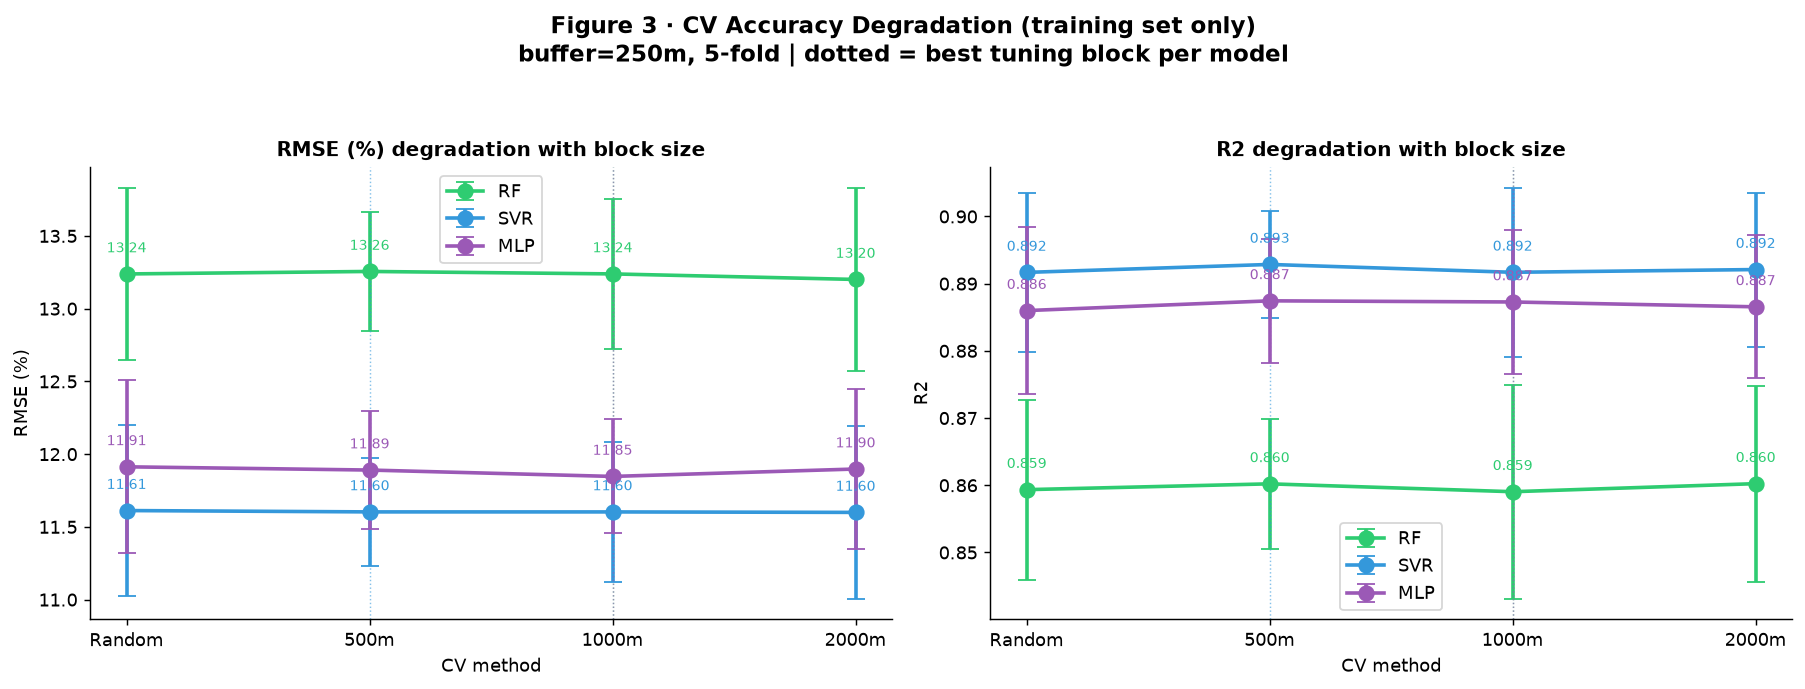

Figure 3 saved.


In [61]:
# Figure 3 -- RMSE & R2 degradation curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for metric, ax, ylabel in [('RMSE', axes[0], 'RMSE (%)'), ('R2', axes[1], 'R2')]:
    for name in tuned_models:
        means = [all_results[(name, l)][metric].mean() for l in CV_LABELS]
        stds  = [all_results[(name, l)][metric].std()  for l in CV_LABELS]
        ax.errorbar(range(len(CV_LABELS)), means, yerr=stds,
                    fmt='o-', color=MODEL_COLORS[name], lw=2, ms=8, capsize=5, label=name)
        for i, m_val in enumerate(means):
            ax.annotate(f'{m_val:.2f}' if metric=='RMSE' else f'{m_val:.3f}',
                        (i, m_val), textcoords='offset points',
                        xytext=(0, 12), ha='center', fontsize=8, color=MODEL_COLORS[name])
        best_b = best_block_per_model[name]
        if best_b in CV_LABELS:
            ax.axvline(CV_LABELS.index(best_b), color=MODEL_COLORS[name],
                       lw=0.8, ls=':', alpha=0.6)
    ax.set_xticks(range(len(CV_LABELS)))
    ax.set_xticklabels(CV_LABELS)
    ax.set_xlabel('CV method'); ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} degradation with block size', fontweight='bold')
    ax.legend(fontsize=10)

fig.suptitle(f'buffer={BUFFER_M}m, {N_FOLDS}-fold | dotted = best tuning block per model',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig03_degradation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 3 saved.')


---
## Cell 11 · Figure 4 — Per-fold RMSE boxplots

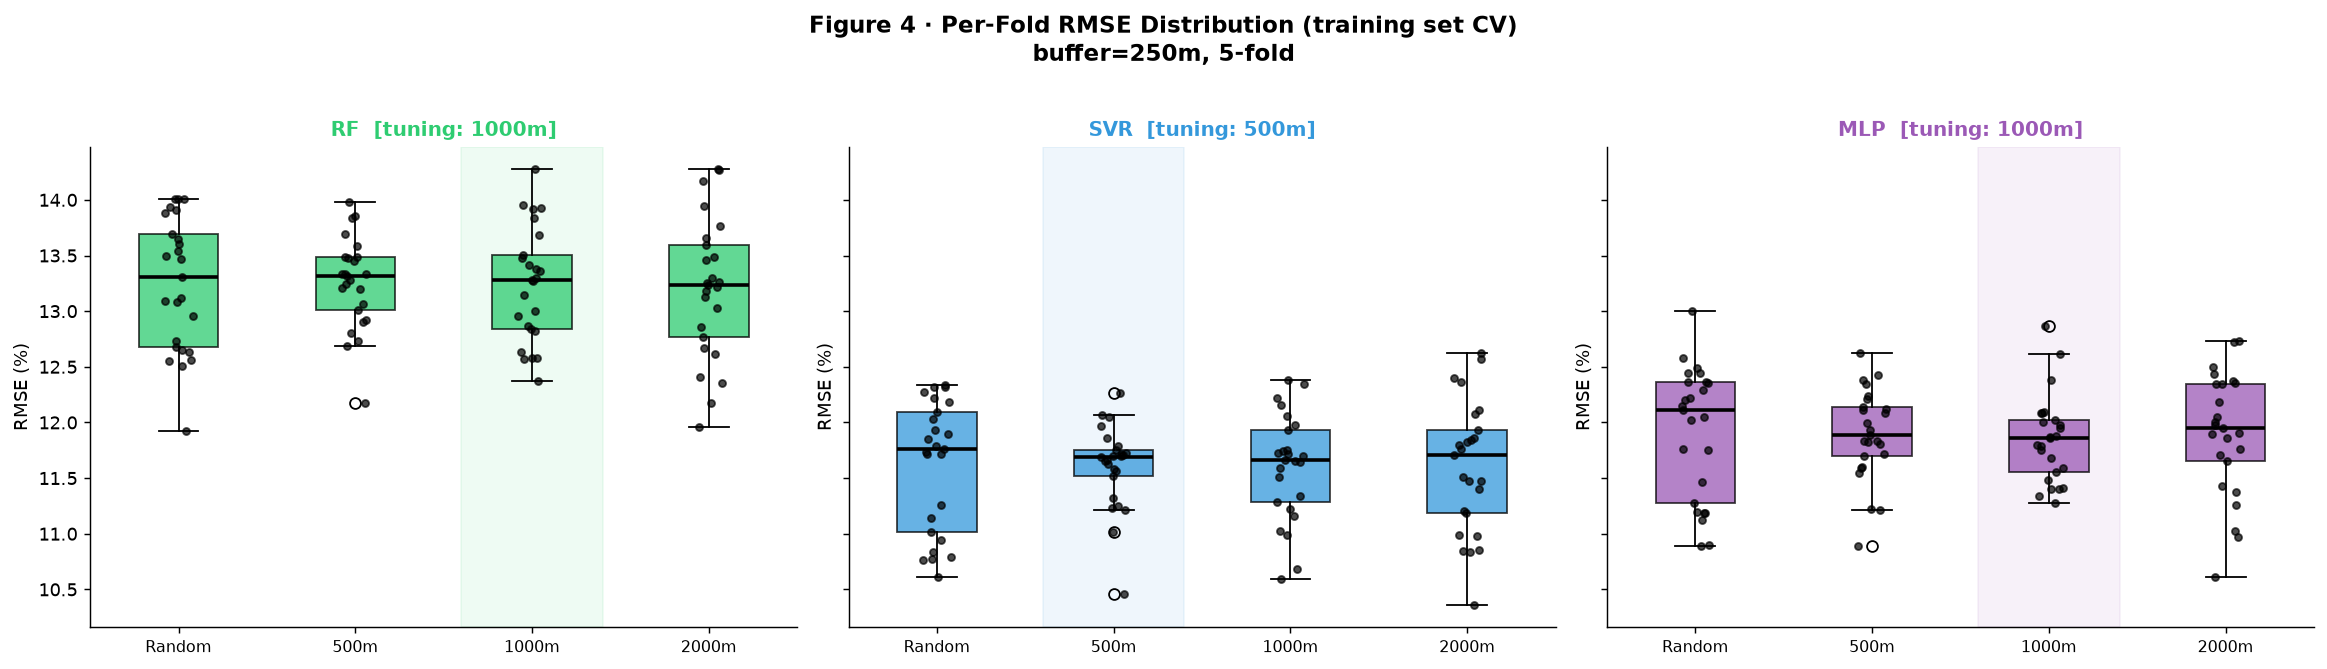

Figure 4 saved.


In [62]:
# Figure 4 -- Per-fold RMSE boxplots
fig, axes = plt.subplots(1, len(tuned_models), figsize=(6 * len(tuned_models), 5),
                         sharey=True, squeeze=False)
for ax, name in zip(axes[0], tuned_models):
    data = [all_results[(name, l)]['RMSE'].values for l in CV_LABELS]
    bp = ax.boxplot(data, patch_artist=True,
                    medianprops={'color': 'black', 'linewidth': 2},
                    whiskerprops={'lw': 1}, capprops={'lw': 1})
    for patch in bp['boxes']:
        patch.set_facecolor(MODEL_COLORS[name]); patch.set_alpha(0.75)
    for i, d in enumerate(data, start=1):
        ax.scatter(np.full(len(d), i) + np.random.uniform(-0.08, 0.08, len(d)),
                   d, c='black', s=15, zorder=5, alpha=0.7)
    best_b = best_block_per_model[name]
    if best_b in CV_LABELS:
        bi = CV_LABELS.index(best_b) + 1
        ax.axvspan(bi-0.4, bi+0.4, alpha=0.08, color=MODEL_COLORS[name])
    ax.set_xticks(range(1, len(CV_LABELS)+1))
    ax.set_xticklabels(CV_LABELS, fontsize=9)
    ax.set_ylabel('RMSE (%)')
    ax.set_title(f'{name}  [tuning: {best_block_per_model[name]}]',
                 fontweight='bold', fontsize=11, color=MODEL_COLORS[name])

fig.suptitle(f'buffer={BUFFER_M}m, {N_FOLDS}-fold', fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig04_rmse_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 4 saved.')


---
## Cell 12 · Figure 5 — All metrics grouped bar chart

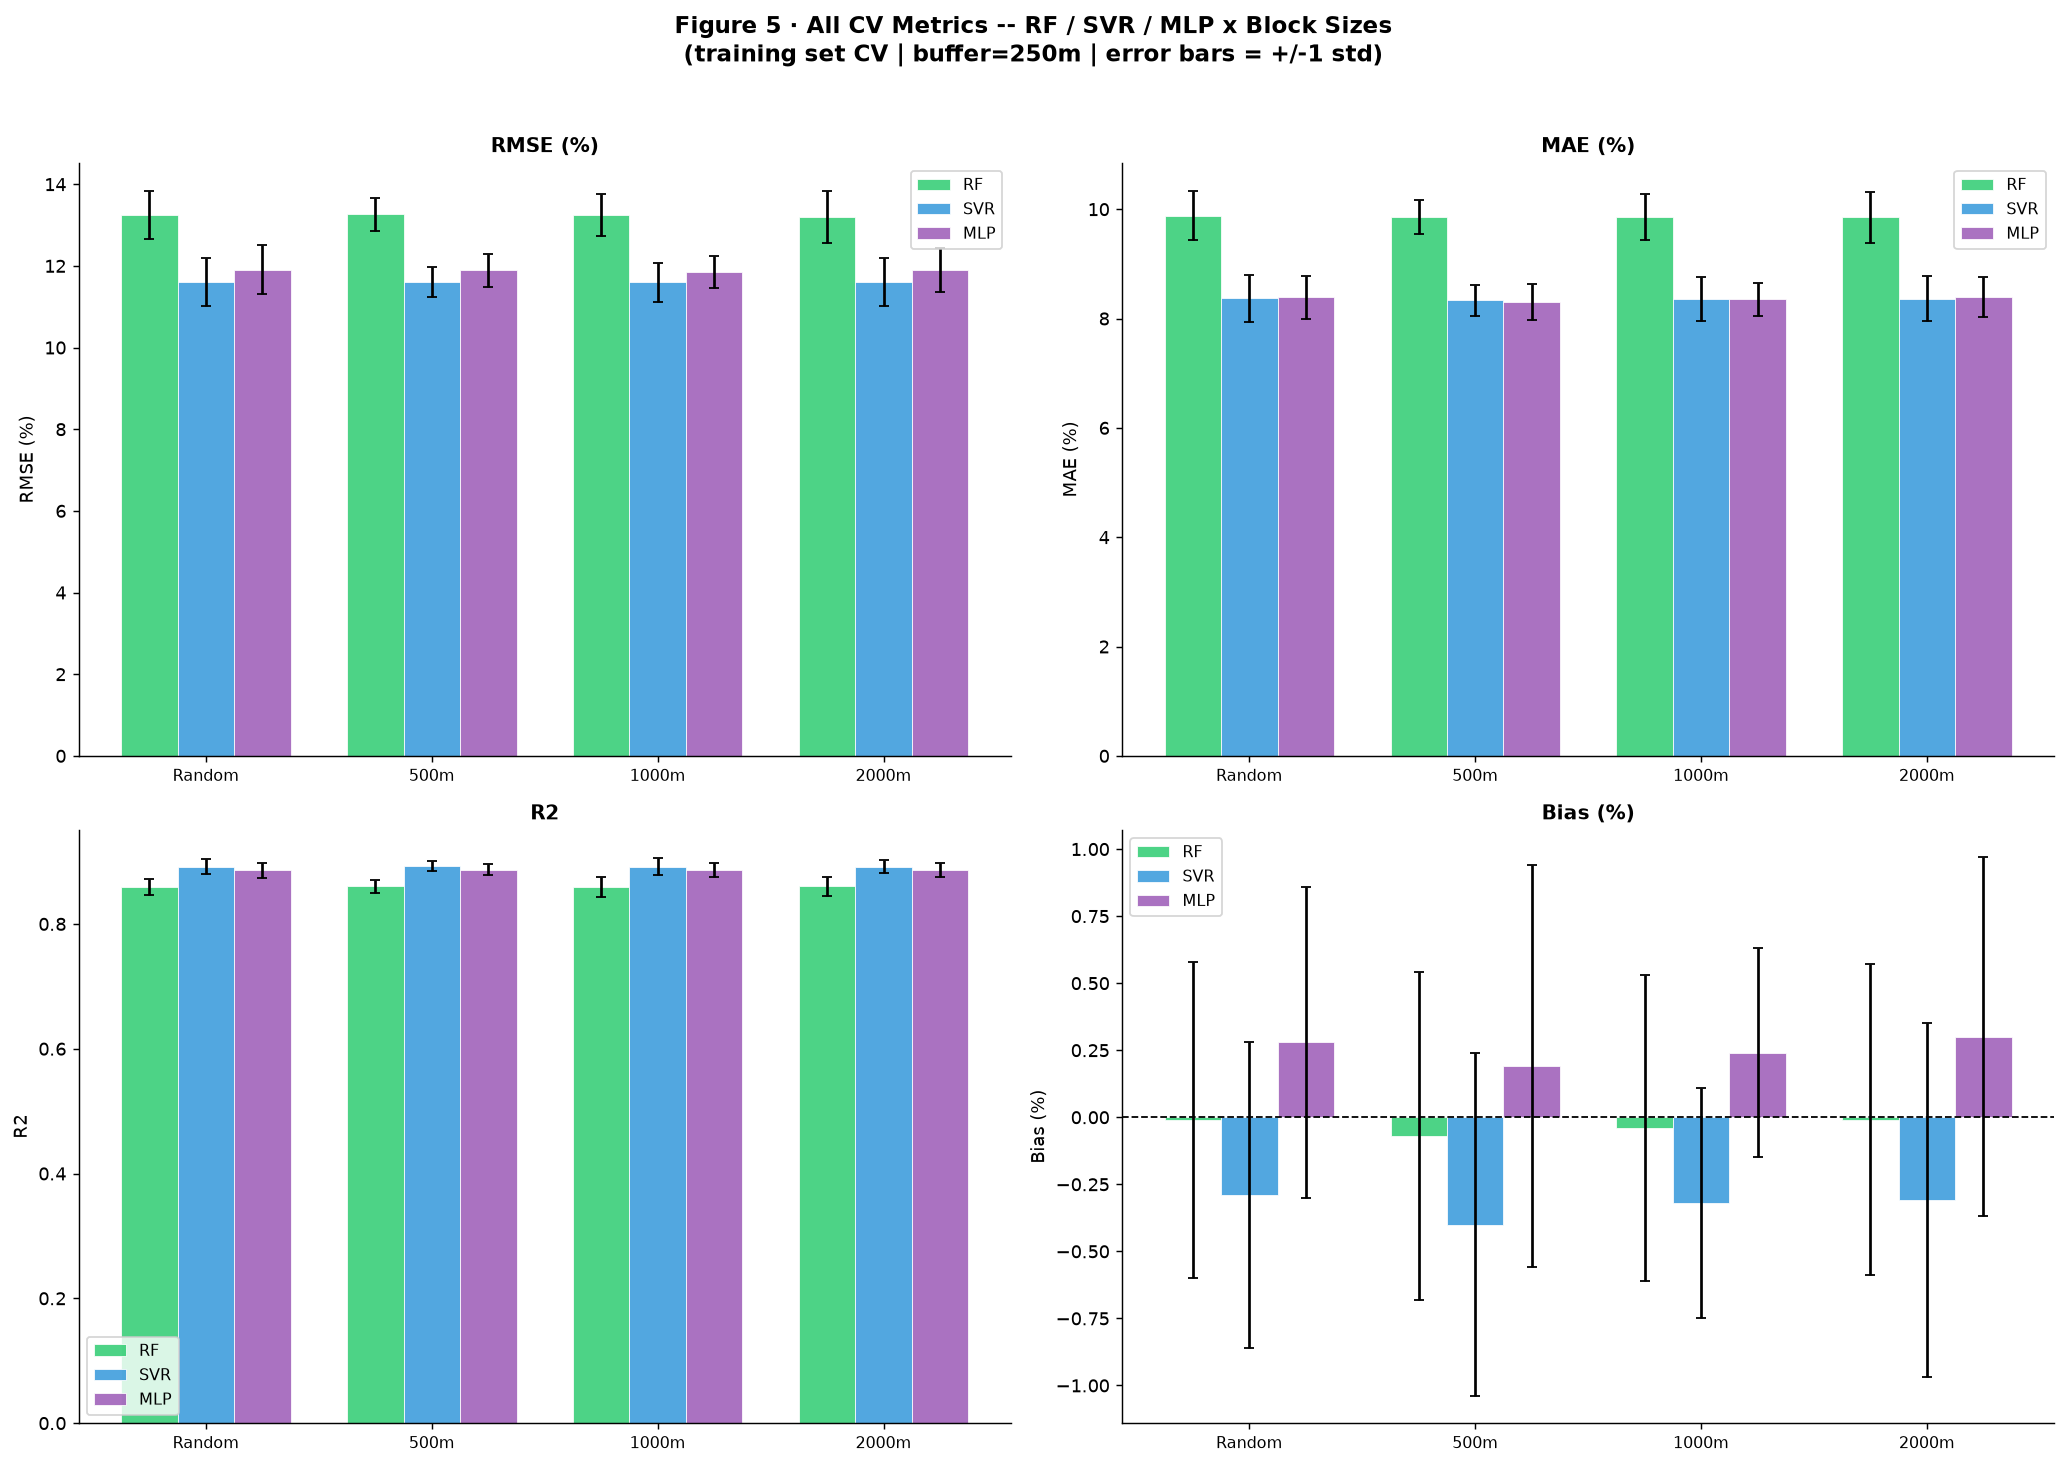

Figure 5 saved.


In [63]:
# Figure 5 -- All metrics grouped bar chart
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.ravel()
metrics_info = [
    ('RMSE_mean', 'RMSE_std', 'RMSE (%)'),
    ('MAE_mean',  'MAE_std',  'MAE (%)'),
    ('R2_mean',   'R2_std',   'R2'),
    ('Bias_mean', 'Bias_std', 'Bias (%)'),
]
model_names = list(tuned_models.keys())
n_models = len(model_names)
x = np.arange(len(CV_LABELS))
width = 0.25
offsets = {m: (i - n_models//2) * width for i, m in enumerate(model_names)}

for ax, (mean_col, std_col, ylabel) in zip(axes, metrics_info):
    for name in model_names:
        sub  = summary_df[summary_df['Model'] == name].set_index('CV_method')
        vals = [sub.loc[l, mean_col] for l in CV_LABELS]
        errs = [sub.loc[l, std_col]  for l in CV_LABELS]
        ax.bar(x + offsets[name], vals, width,
               color=MODEL_COLORS[name], alpha=0.85,
               label=name, edgecolor='white', lw=0.5,
               yerr=errs, capsize=3)
    if mean_col == 'Bias_mean':
        ax.axhline(0, color='black', lw=1, ls='--')
    ax.set_xticks(x)
    ax.set_xticklabels(CV_LABELS, fontsize=9)
    ax.set_ylabel(ylabel); ax.set_title(ylabel, fontweight='bold')
    ax.legend(fontsize=9)

fig.suptitle(f'training set CV | buffer={BUFFER_M}m | error bars = +/-1 std',
             fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig05_all_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 5 saved.')


---
## Cell 13 · Figure 6 — Spatial autocorrelation inflation heatmap

   SPATIAL AUTOCORRELATION INFLATION (training set CV)
   Buffer=250m | Folds=5 | Reference: Random CV

  RF  |  Random: RMSE=13.24%  R2=0.859  |  tuning block=1000m
    500m  : RMSE=13.26%  R2=0.860  (+0.02pp, +0.1%)
    1000m : RMSE=13.24%  R2=0.859  (+0.00pp, +0.0%) <- tuning block
    2000m : RMSE=13.20%  R2=0.860  (-0.04pp, -0.3%)

  SVR  |  Random: RMSE=11.61%  R2=0.892  |  tuning block=500m
    500m  : RMSE=11.60%  R2=0.893  (-0.01pp, -0.1%) <- tuning block
    1000m : RMSE=11.60%  R2=0.892  (-0.01pp, -0.1%)
    2000m : RMSE=11.60%  R2=0.892  (-0.01pp, -0.1%)

  MLP  |  Random: RMSE=11.91%  R2=0.886  |  tuning block=1000m
    500m  : RMSE=11.89%  R2=0.887  (-0.02pp, -0.2%)
    1000m : RMSE=11.85%  R2=0.887  (-0.07pp, -0.6%) <- tuning block
    2000m : RMSE=11.90%  R2=0.887  (-0.02pp, -0.1%)


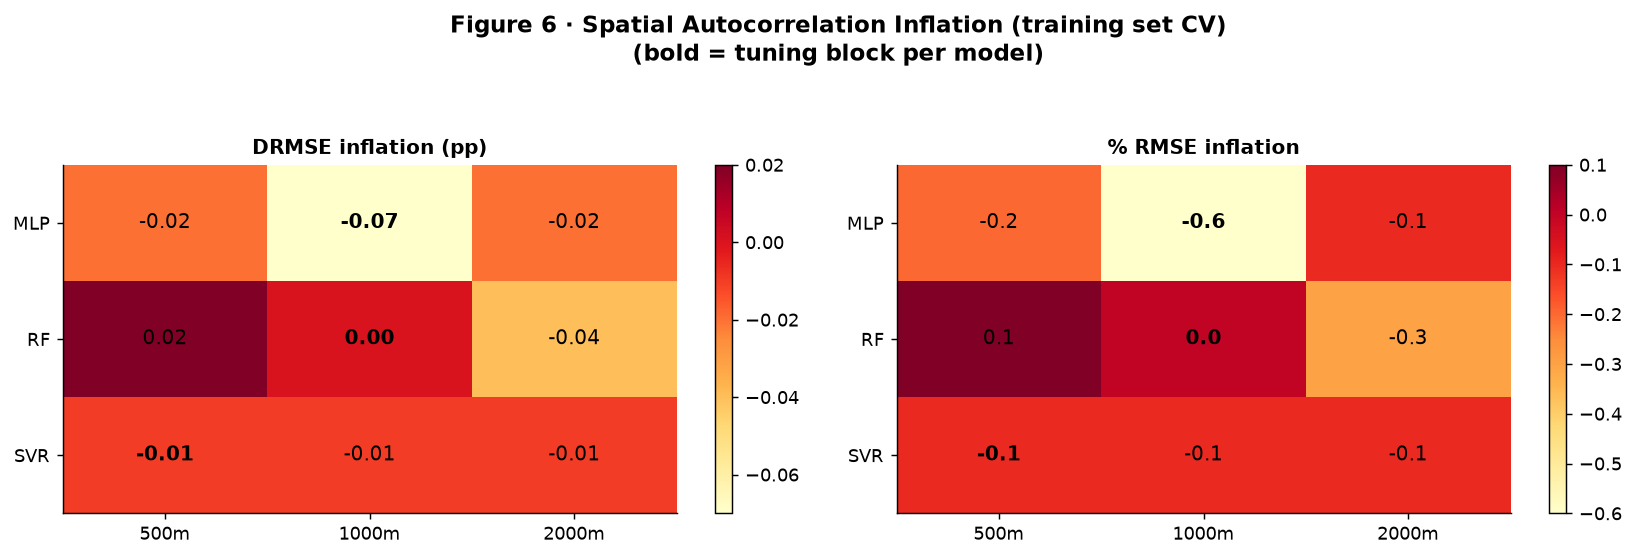

Figure 6 saved.


In [64]:
# Figure 6 -- Spatial autocorrelation inflation heatmap
print('='*65)
print('   SPATIAL AUTOCORRELATION INFLATION (training set CV)')
print(f'   Buffer={BUFFER_M}m | Folds={N_FOLDS} | Reference: Random CV')
print('='*65)

inflation_rows = []
for name in tuned_models:
    rnd_rmse = all_results[(name, 'Random')]['RMSE'].mean()
    rnd_r2   = all_results[(name, 'Random')]['R2'].mean()
    best_b   = best_block_per_model[name]
    print(f'\n  {name}  |  Random: RMSE={rnd_rmse:.2f}%  R2={rnd_r2:.3f}  |  tuning block={best_b}')
    for bs in BLOCK_SIZES:
        label   = f'{bs}m'
        sp_rmse = all_results[(name, label)]['RMSE'].mean()
        sp_r2   = all_results[(name, label)]['R2'].mean()
        diff    = sp_rmse - rnd_rmse
        pct     = 100 * diff / rnd_rmse
        marker  = ' <- tuning block' if label == best_b else ''
        print(f'    {label:<6}: RMSE={sp_rmse:.2f}%  R2={sp_r2:.3f}  ' +
              f'({diff:+.2f}pp, {pct:+.1f}%){marker}')
        inflation_rows.append({
            'Model': name, 'Block': label,
            'Random_RMSE': round(rnd_rmse, 2), 'Spatial_RMSE': round(sp_rmse, 2),
            'RMSE_diff': round(diff, 2), 'Pct_inflation': round(pct, 1),
            'Tuning_block': best_b,
        })

infl_df = pd.DataFrame(inflation_rows)
infl_df.to_csv(f'{OUTPUT_DIR}/inflation_analysis.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, fmt in [
    (axes[0], 'RMSE_diff',     'DRMSE inflation (pp)', '.2f'),
    (axes[1], 'Pct_inflation', '% RMSE inflation',     '.1f'),
]:
    pivot = infl_df.pivot(index='Model', columns='Block', values=col)
    pivot = pivot[[f'{bs}m' for bs in BLOCK_SIZES]]
    im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(len(BLOCK_SIZES)))
    ax.set_xticklabels([f'{bs}m' for bs in BLOCK_SIZES])
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            is_best = (f'{BLOCK_SIZES[j]}m' == best_block_per_model[pivot.index[i]])
            ax.text(j, i, f'{pivot.values[i,j]:{fmt}}',
                    ha='center', va='center', fontsize=11,
                    fontweight='bold' if is_best else 'normal')
    ax.set_title(title, fontweight='bold')
    plt.colorbar(im, ax=ax)

fig.suptitle('bold = tuning block per model', fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig06_inflation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 6 saved.')


---
## Cell 14 · GEE raster export

Retrain RF on the full training set and export its raster. The Earth Engine
forest is built from every tuned setting by `gee_models.rf_classifier` and
compared with the scikit-learn forest before export. The raster is exported to
Google Drive and downloaded to `RF_RASTER_PATH` automatically; the cell waits
until it is saved (see `gee_export.py`).

In [65]:
# Retrain RF on the full training set, then build the same forest in Earth
# Engine and export its raster. RF is the only model: it is the one the
# Vietnam transferability notebooks apply.
rf_fitted = clone(tuned_models['RF'])
rf_fitted.fit(X_train, y_train)
joblib.dump(rf_fitted, f'{OUTPUT_DIR}/best_model_RF_spatialcv.joblib')

# Every tuned setting reaches Earth Engine (gee_models.py), and the forest is
# trained on the same points as rf_fitted.
rf_params  = rf_fitted.get_params()
gee_params = rf_gee_params(rf_params, len(band_names))
print('Earth Engine RF:', gee_params)
gee_rf = rf_classifier(rf_params, len(band_names), seed=RANDOM_STATE).train(
    features=training_fc(gdf_train, band_names, 'IMD'),
    classProperty='IMD', inputProperties=band_names)

# Check the two forests agree, on the sample points.
compare_predictions(gee_rf, rf_fitted, X_train, band_names)

# Save metadata for Notebook 02
meta = {
    'best_model_name': BEST_MODEL_NAME,
    'best_block':      BEST_BLOCK_LABEL,
    'band_names':      band_names,
    'best_params':     {k: str(v) for k, v in rf_params.items()},
    'gee_params':      gee_params,
    # No holdout: the accuracy carried forward is the spatial CV at the chosen
    # block (mean over folds and repeats). Bias is observed minus predicted.
    'cv_block':        BEST_BLOCK_LABEL,
    'cv_rmse':         float(all_results[('RF', BEST_BLOCK_LABEL)]['RMSE'].mean()),
    'cv_mae':          float(all_results[('RF', BEST_BLOCK_LABEL)]['MAE'].mean()),
    'cv_r2':           float(all_results[('RF', BEST_BLOCK_LABEL)]['R2'].mean()),
    'cv_bias':         float(all_results[('RF', BEST_BLOCK_LABEL)]['Bias'].mean()),
}
with open(f'{OUTPUT_DIR}/model_metadata_spatialcv.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('RF model and metadata saved for Vietnam transferability.')

# Export, then wait and download to the path Cell 15 reads.
prediction_rf = (aef_img.classify(gee_rf).rename('IMD_predicted')
                 .clip(aoi_geom).updateMask(non_water_mask))
wait_and_download([start_export(prediction_rf, RF_RASTER_PATH,
                                region=aoi_geom, crs='EPSG:32632')])

print(f'\nBest model: {BEST_MODEL_NAME} @ {BEST_BLOCK_LABEL}')


RF model and metadata saved for Vietnam transferability.
Training GEE RF...
  Export started: IMD_predicted_RF_spatialCV2_Milan
Training GEE SVR...
  Export started: IMD_predicted_SVR_spatialCV2_Milan

Best model: SVR @ 500m
Download GeoTIFFs from Google Drive before Cell 15.


---
## Cell 20 · Figure D — Feature importance (RF)

In [ ]:
# Figure D -- Feature importance (RF)
# No held-out set, so permutation importance is computed on the points the
# model was fitted on (in-sample): it ranks the bands the model relies on and
# is not an accuracy measure.
rf_model = rf_fitted
print('Computing permutation importance (in-sample)...')
perm     = permutation_importance(rf_model, X_train, y_train,
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=N_JOBS)
sort_idx = np.argsort(perm.importances_mean)[::-1]

# Persist the importances. Figure D alone cannot be cited: reading band
# names off a 50-bar plot is guesswork, and any claim about WHICH features
# carry the signal needs the numbers on disk. Sorted by permutation
# importance (in-sample), with impurity alongside.
imp_df = pd.DataFrame({
    'band':                band_names,
    'impurity_importance': rf_model.feature_importances_,
    'perm_importance':     perm.importances_mean,
    'perm_std':            perm.importances_std,
}).sort_values('perm_importance', ascending=False).reset_index(drop=True)
imp_df['rank'] = imp_df.index + 1
imp_df.to_csv(f'{OUTPUT_DIR}/feature_importance_RF.csv', index=False)
print(f'Saved {OUTPUT_DIR}/feature_importance_RF.csv  '
      f'({len(imp_df)} bands; top: '
      f'{", ".join(imp_df["band"].head(4))})')

fig, axes_d = plt.subplots(1, 2, figsize=(16, 5))
ax = axes_d[0]
imp = rf_model.feature_importances_
ax.bar(range(len(band_names)), imp[sort_idx],
       color=plt.cm.viridis(imp[sort_idx]/imp.max()), edgecolor='none')
ax.set_xticks(range(len(band_names)))
ax.set_xticklabels([band_names[i] for i in sort_idx], rotation=90, fontsize=7)
ax.set_ylabel('Mean Decrease Impurity')
ax.set_title('RF Impurity Importance', fontweight='bold')

ax = axes_d[1]
top20 = sort_idx[:20]
ax.barh(range(20), perm.importances_mean[top20][::-1],
        xerr=perm.importances_std[top20][::-1],
        color=MODEL_COLORS['RF'], alpha=0.85, edgecolor='none',
        error_kw={'linewidth': 0.8, 'color': 'black'})
ax.set_yticks(range(20))
ax.set_yticklabels([band_names[i] for i in top20[::-1]], fontsize=8)
ax.set_xlabel('Mean accuracy decrease (RMSE units, in-sample)')
ax.set_title('Permutation Importance -- Top 20 (RF)', fontweight='bold')

fig.suptitle(f'RF (tuning block={best_block_per_model["RF"]})',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/figD_importance_RF.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure D saved.')


---
## Cell 21 · Figure E — Raster comparison map

In [72]:
# Figure E -- Raster comparison
DISPLAY_SCALE = 2
IMD_OBS_PATH  = 'data/CLMS_2018_Milan_LAEA.tif'
IMD_PRED_PATH = RF_RASTER_PATH

imd_obs  = rxr.open_rasterio(IMD_OBS_PATH,  masked=False).squeeze('band', drop=True)[::DISPLAY_SCALE, ::DISPLAY_SCALE]
imd_pred = rxr.open_rasterio(IMD_PRED_PATH, masked=False).squeeze('band', drop=True)[::DISPLAY_SCALE, ::DISPLAY_SCALE]
if imd_pred.rio.crs != imd_obs.rio.crs or imd_pred.shape != imd_obs.shape:
    imd_pred = imd_pred.rio.reproject_match(imd_obs)
imd_diff = imd_pred - imd_obs
imd_cmap = ListedColormap(['#1a9641','#a6d96a','#ffffbf','#fdae61','#d7191c'])

def imshow_aspect(ax, da, **kw):
    b  = da.rio.bounds()
    im = ax.imshow(da.values, extent=(b[0], b[2], b[1], b[3]), **kw)
    ax.set_aspect('equal')
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4))
    ax.tick_params(axis='both', labelsize=8)
    ax.set_xlabel('Easting [m]', fontsize=9); ax.set_ylabel('Northing [m]', fontsize=9)
    return im

fig, axes_e = plt.subplots(2, 2, figsize=(15, 12), gridspec_kw={'wspace': 0.25, 'hspace': 0.04})
im1 = imshow_aspect(axes_e[0,0], imd_obs,  cmap=imd_cmap, vmin=0, vmax=100)
axes_e[0,0].set_title('Observed IMD (CLMS 2018)', fontweight='bold', fontsize=12)
im2 = imshow_aspect(axes_e[0,1], imd_pred, cmap=imd_cmap, vmin=0, vmax=100)
axes_e[0,1].set_title(f'Predicted IMD', fontweight='bold', fontsize=12)
im3 = imshow_aspect(axes_e[1,0], imd_diff, cmap='RdBu_r', vmin=-30, vmax=30)
axes_e[1,0].set_title('Difference (Predicted - Observed)', fontweight='bold', fontsize=12)
axes_e[1,1].axis('off')

fig.colorbar(im1, ax=axes_e[0,:], orientation='vertical', fraction=0.025, pad=0.02, label='IMD (%)')
fig.colorbar(im3, ax=axes_e[1,:], orientation='vertical', fraction=0.025, pad=0.02, label='Pred - Obs (%)')
# fig.suptitle(f'Figure E · IMD Observed vs Predicted vs Difference -- Milan\n' +
#             f'RF + AEF | tuning block={best_block_per_model["RF"]} | spatial test pts shown',
#             fontsize=13, fontweight='bold', y=1.01)
plt.savefig(f'{OUTPUT_DIR}/figE_raster_comparison_1.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure E saved.')

CPLE_NotSupportedError: Cannot find coordinate operations from '{   "$schema": "https://proj.org/schemas/v0.7/projjson.schema.json",   "type": "ProjectedCRS",   "name": "WGS 84 / UTM zone 32N",   "base_crs": {     "type": "GeographicCRS",     "name": "WGS 84",     "datum": {       "type": "GeodeticReferenceFrame",       "name": "World Geodetic System 1984",       "ellipsoid": {         "name": "WGS 84",         "semi_major_axis": 6378137,         "inverse_flattening": 298.257223563       }     },     "coordinate_system": {       "subtype": "ellipsoidal",       "axis": [         {           "name": "Longitude",           "abbreviation": "lon",           "direction": "east",           "unit": "degree"         },         {           "name": "Latitude",           "abbreviation": "lat",           "direction": "north",           "unit": "degree"         }       ]     }   },   "conversion": {     "name": "UTM zone 32N",     "method": {       "name": "Transverse Mercator",       "id": {       

---
## Cell 22 · Final summary

In [ ]:
print('='*75)
print('   FINAL SUMMARY -- ALL POINTS, SPATIAL CV')
print('='*75)

print('\n1. HYPERPARAMETER TUNING (spatial block CV, all points):')
for name in tuned_models:
    b    = best_block_per_model[name]
    rmse = tune_df[(tune_df['Model']==name) & (tune_df['Block']==b)]['CV_RMSE'].values[0]
    print(f'  {name:<8}: best block={b}  CV RMSE={rmse:.3f}')

print(f'\n2. SPATIAL CV EVALUATION (buffer={BUFFER_M}m, {N_FOLDS}-fold, all points):')
pivot = summary_df.pivot_table(index='Model', columns='CV_method', values='RMSE_mean')[CV_LABELS]
print(pivot.round(2).to_string())

print(f'\n* Best model: {BEST_MODEL_NAME} @ {BEST_BLOCK_LABEL}')

print('\n3. SPATIAL AUTOCORRELATION INFLATION:')
for name in tuned_models:
    b   = best_block_per_model[name]
    rnd = all_results[(name, 'Random')]['RMSE'].mean()
    sp  = all_results[(name, b)]['RMSE'].mean()
    print(f'  {name}: {sp-rnd:+.2f}% RMSE ({100*(sp-rnd)/rnd:+.1f}% relative) at {b} blocks')

print('\nOutputs:')
for f in sorted(os.listdir(OUTPUT_DIR)):
    sz = os.path.getsize(os.path.join(OUTPUT_DIR, f))
    print(f'  {f:<50} {sz/1024:>8.1f} kB')
print('='*75)

   FINAL SUMMARY -- SPATIALLY STRATIFIED DESIGN

0. SPATIAL TRAIN/TEST SPLIT (1000m blocks, 250m buffer):
   Train: 2449 pts | Test: 1014 pts
   Test fraction: 29.3%

1. HYPERPARAMETER TUNING (spatial block CV on training set):
  RF      : best block=1000m  CV RMSE=13.162
  SVR     : best block=500m  CV RMSE=11.711
  MLP     : best block=500m  CV RMSE=12.020

2. SPATIAL CV EVALUATION (buffer=250m, 5-fold, training set only):
CV_method  Random   500m  1000m  2000m
Model                                 
MLP         12.04  12.04  12.07  12.02
RF          13.24  13.26  13.24  13.20
SVR         11.61  11.60  11.60  11.60

3. SPATIAL HOLDOUT TEST SET:
  Model   RMSE    MAE    R2  Bias
 GEE_RF 14.123 10.675 0.837 0.624
GEE_SVR 14.756 11.400 0.822 0.274

* Best model: SVR @ 500m

4. SPATIAL AUTOCORRELATION INFLATION:
  RF: +0.00% RMSE (+0.0% relative) at 1000m blocks
  SVR: -0.01% RMSE (-0.1% relative) at 500m blocks
  MLP: -0.01% RMSE (-0.0% relative) at 500m blocks

Outputs:
  IMD_predicted_